<a href="https://colab.research.google.com/github/jwoo25/TUK-SMT-Multimodal-AI/blob/main/notebooks/Result1_ResNet50_1DCNN_NoAug.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import glob
import subprocess

# 1. 구글 드라이브의 원본 최상위 폴더 경로 (수정 필요)
DRIVE_ROOT = "/content/drive/MyDrive/18.SMT 공정 개선 멀티모달 데이터"
COLAB_ROOT = "/content/smt_data"

print("1. 구글 드라이브 데이터를 코랩으로 복사 중입니다... (시간이 소요될 수 있습니다)")
!mkdir -p "{COLAB_ROOT}"
!cp -r "{DRIVE_ROOT}/"* "{COLAB_ROOT}/"

# 2. 복사된 폴더 내의 모든 .zip 파일 찾기
zip_files = glob.glob(f"{COLAB_ROOT}/**/*.zip", recursive=True)
print(f"\n2. 총 {len(zip_files)}개의 압축 파일을 찾았습니다. 압축 해제를 시작합니다...")

# 3. 찾은 zip 파일들을 각각 풀고 원본 zip은 삭제
for zip_path in zip_files:
    extract_dir = os.path.dirname(zip_path) # zip 파일이 있던 바로 그 폴더
    # 조용히(-q) 덮어쓰기(-o)로 풀기
    subprocess.run(['unzip', '-q', '-o', zip_path, '-d', extract_dir])
    # 다 풀면 용량 확보를 위해 zip 파일 삭제
    os.remove(zip_path)

print("✅ 모든 데이터의 압축 해제 및 정리가 완료되었습니다!")

1. 구글 드라이브 데이터를 코랩으로 복사 중입니다... (시간이 소요될 수 있습니다)

2. 총 216개의 압축 파일을 찾았습니다. 압축 해제를 시작합니다...
✅ 모든 데이터의 압축 해제 및 정리가 완료되었습니다!


In [ ]:
import glob
import json

# 압축 푼 폴더 안에서 아무 json 파일이나 1개만 찾아옵니다.
json_files = glob.glob("/content/smt_data/**/*.json", recursive=True)

if len(json_files) > 0:
    sample_path = json_files[0]
    print(f"✅ 테스트로 열어본 파일: {sample_path}\n")

    with open(sample_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    print("🔍 [JSON 뼈대 구조 출력 (처음 1000자)]")
    print(json.dumps(data, indent=2, ensure_ascii=False)[:1000])
else:
    print("❌ JSON 파일을 찾지 못했습니다. 경로가 맞는지 확인해주세요.")

✅ 테스트로 열어본 파일: /content/smt_data/3.개방데이터/1.데이터/Training/02.라벨링데이터/PR_NOR_NB_A_20250902-155347_00993.json

🔍 [JSON 뼈대 구조 출력 (처음 1000자)]
{
  "categories": [
    {
      "id": 1,
      "name": "정상_미납"
    },
    {
      "id": 2,
      "name": "정상_납부족"
    },
    {
      "id": 3,
      "name": "정상_납쇼트"
    },
    {
      "id": 4,
      "name": "정상_납볼"
    },
    {
      "id": 5,
      "name": "정상_납좌표밀림"
    },
    {
      "id": 6,
      "name": "정상_납형성불량"
    },
    {
      "id": 7,
      "name": "정상_냉납"
    },
    {
      "id": 8,
      "name": "정상_밀림"
    },
    {
      "id": 9,
      "name": "정상_쇼트"
    },
    {
      "id": 10,
      "name": "정상_오삽"
    },
    {
      "id": 11,
      "name": "정상_미삽"
    },
    {
      "id": 12,
      "name": "정상_역삽"
    },
    {
      "id": 13,
      "name": "정상_뒤집힘"
    },
    {
      "id": 14,
      "name": "정상_일어섬"
    },
    {
      "id": 15,
      "name": "정상_납금감/핀홀"
    },
    {
      "id": 16,
      "name": "정상_납고드름"
    },
    {

In [ ]:
import glob
import json

json_files = glob.glob("/content/smt_data/**/*.json", recursive=True)

if len(json_files) > 0:
    sample_path = json_files[0]
    with open(sample_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    print(f"✅ 열어본 파일: {sample_path}\n")
    print(f"🔑 최상위 항목(Keys): {list(data.keys())}\n")

    # 너무 긴 categories를 제외하고 나머지 진짜 데이터들의 뼈대만 출력
    for key in data.keys():
        if key != 'categories':
            print(f"--- [{key}] 내용 미리보기 ---")
            print(str(data[key])[:500], "...\n")
else:
    print("❌ JSON 파일을 찾지 못했습니다.")

✅ 열어본 파일: /content/smt_data/3.개방데이터/1.데이터/Training/02.라벨링데이터/PR_NOR_NB_A_20250902-155347_00993.json

🔑 최상위 항목(Keys): ['categories', 'images', 'annotations', 'sensor_data']

--- [images] 내용 미리보기 ---
[{'id': 717, 'width': 512, 'height': 512, 'file_name': 'PR_NOR_NB_A_20250902-155347_00993.jpg'}] ...

--- [annotations] 내용 미리보기 ---
[{'id': 3708, 'image_id': 717, 'category_id': 2, 'segmentation': [], 'area': 9085.320600000001, 'bbox': [74.75, 114.36, 129.31, 70.26], 'iscrowd': 0, 'attributes': {'occluded': False, 'rotation': 0.0}}, {'id': 3709, 'image_id': 717, 'category_id': 2, 'segmentation': [], 'area': 10243.519499999999, 'bbox': [71.01, 231.71, 133.05, 76.99], 'iscrowd': 0, 'attributes': {'occluded': False, 'rotation': 0.0}}, {'id': 3710, 'image_id': 717, 'category_id': 2, 'segmentation': [], 'area': 9252.94, 'bbox': [ ...

--- [sensor_data] 내용 미리보기 ---
[{'image_id': 717, 'sensor_sequence': [{'timestamp': '2025-09-02 15:53:47', 'temperature': 23.81, 'humidity': 55.73, 

🚀 [SYSTEM] 실행 장치: cuda | 실험명: Result1_ResNet50_1DCNN_NoAug

🔍 [STEP 1] 전체 디스크 스캔 및 JSON 고속 파싱 중...
   -> 발견된 원본 파일: 이미지 46,220장 | JSON 46,220개


JSON 파싱:   0%|          | 0/46220 [00:00<?, ?it/s]


📊 [데이터셋 엄격 분할 결과 (누수 0건 검증 완료)]
   ✅ Train     : 총 32,868개 (정상: 11,401개 / 불량: 21,467개)
   ✅ Val       : 총 8,217개 (정상: 2,850개 / 불량: 5,367개)
   ✅ Test(봉인)  : 총 5,135개 (정상: 1,786개 / 불량: 3,349개)

📐 [센서 StandardScaler 통계 (Train 기준)]
   - temperature  : mean =  24.9915, std =   1.1885
   - humidity     : mean =  53.0403, std =   9.2074
   - vibration    : mean =   0.3801, std =   0.1104
   - acceleration : mean =   0.0281, std =   0.0111
   - noise        : mean =  69.8080, std =   6.9814

🧠 [MODEL] resnet50 + 1d_cnn | 파라미터 수: 24.13M

🔥 [STEP 2] 정식 10 에폭 학습 시작 (저장 위치: /content/drive/MyDrive/SMT_Experiments)


Epoch 1/10 [Train]:   0%|          | 0/256 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/65 [00:00<?, ?it/s]

Epoch [01/10] (lr=0.000293) | Train Loss: 0.1320, Acc: 0.9514, F1: 0.9627 || Val Loss: 0.0712, Acc: 0.9742, Rec: 0.9871, F1: 0.9804, AUC: 0.9962
   ⭐ [SAVE] 최고 Val F1 (0.9804) 갱신! 체크포인트 저장 완료.


... (26 outputs left out)

Epoch [10/10] (lr=0.000001) | Train Loss: 0.0004, Acc: 1.0000, F1: 1.0000 || Val Loss: 0.0386, Acc: 0.9901, Rec: 0.9916, F1: 0.9924, AUC: 0.9991

✅ 학습 완료! 총 소요 시간: 51.6분

🧪 [STEP 3] 최고 성능 모델 로드 후 봉인된 독립 Test Set 평가 중...


[Independent Test]:   0%|          | 0/41 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fba6ffd9bc0>
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fba6ffd9bc0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
        self._shutdown_workers()
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():    if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/lib/python3.13/multiprocessing/proce


🏆 최종 독립 Test 성적표 — Result1_ResNet50_1DCNN_NoAug (Best Epoch: 8)
  • Accuracy  : 99.08%
  • Precision : 99.67%
  • Recall    : 98.93%  (불량 검출률)
  • F1-Score  : 99.30%
  • ROC-AUC   : 0.9990
  • Latency   : 8.92 ms / image (batch=1) | Params: 24.13M


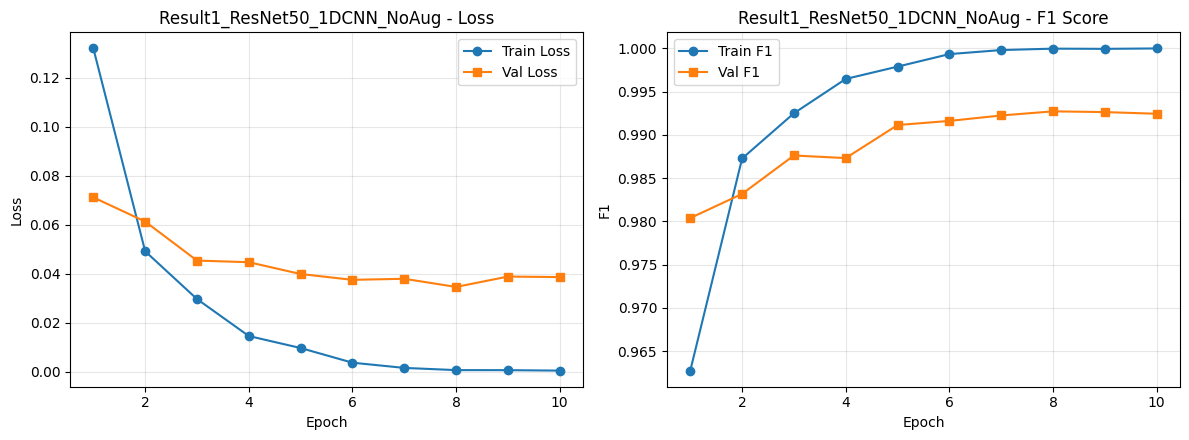

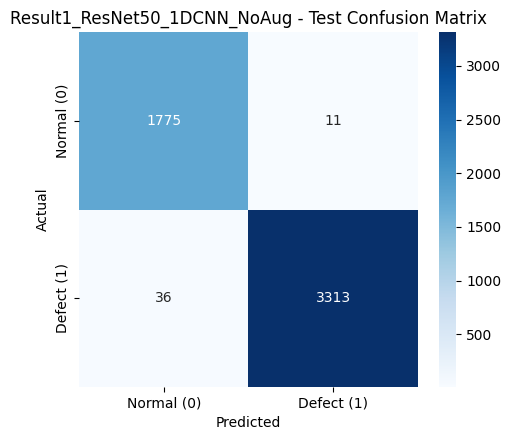

📁 모든 결과물(pth, csv, json, 그래프 2장)이 '/content/drive/MyDrive/SMT_Experiments'에 저장되었습니다.


In [ ]:
import os
import glob
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

# =====================================================================
# 0. 실험 설정 (나중에 Result 2~5, 증강 비교, AWS 이관 시 여기만 수정!)
# =====================================================================
CONFIG = {
    "exp_name": "Result1_ResNet50_1DCNN_NoAug",  # 실험 이름 (저장 파일명에 자동 반영)
    "data_root": "/content/smt_data",            # AWS 이관 시 데이터 경로만 수정
    "save_dir": "/content/drive/MyDrive/SMT_Experiments",
    "vision_backbone": "resnet50",               # 선택: 'resnet50', 'efficientnet_b0', 'convnext_tiny'
    "sensor_backbone": "1d_cnn",                 # 선택: '1d_cnn', 'bilstm', 'transformer'
    "use_augmentation": False,                   # Result 1 기준점은 False, 증강 실험 시 True로 변경
    "epochs": 10,
    "batch_size": 128,                           # OOM 발생 시 64로 축소
    "lr": 3e-4,
    "weight_decay": 1e-4,
    "seed": 42,
    "num_workers": 2,
}

os.makedirs(CONFIG["save_dir"], exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 [SYSTEM] 실행 장치: {device} | 실험명: {CONFIG['exp_name']}")


# =====================================================================
# 1. 고속 메타데이터 & 센서 사전 로딩 (중복 제거 + 다중 BBox 라벨 검수)
# =====================================================================
SENSOR_FEATURES = ['temperature', 'humidity', 'vibration', 'acceleration', 'noise']

def parse_single_json(args):
    json_path, image_dict = args
    base_name = os.path.splitext(os.path.basename(json_path))[0]
    if base_name not in image_dict:
        return None

    try:
        with open(json_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
    except Exception:
        return None

    # 1) 다중 annotations 전체 확인 (하나라도 불량이면 불량(1))
    label = None
    annotations = data.get('annotations', [])
    cat_map = {
        int(c['id']): str(c['name'])
        for c in data.get('categories', [])
        if 'id' in c and 'name' in c
    }

    if len(annotations) > 0:
        is_defect = False
        found_valid = False
        for ann in annotations:
            if ann.get('category_id') is not None:
                found_valid = True
                cat_id = int(ann['category_id'])
                cat_name = cat_map.get(cat_id, '')
                if (cat_name and '불량' in cat_name) or (not cat_name and cat_id >= 17):
                    is_defect = True
                    break
        if found_valid:
            label = 1 if is_defect else 0

    # 예외 시 파일명(_DEF_) 또는 경로로 보조 판별
    if label is None:
        label = 1 if ('_DEF_' in base_name.upper() or '불량' in json_path) else 0

    # 2) 센서 시계열 (5 steps x 5 features) 추출 (None 결측치 방어 포함)
    sensor_arr = np.zeros((5, 5), dtype=np.float32)
    sensor_data_list = data.get('sensor_data', [])
    if len(sensor_data_list) > 0:
        sensor_seq = sensor_data_list[0].get('sensor_sequence', [])
        rows = min(len(sensor_seq), 5)
        for i in range(rows):
            step = sensor_seq[i]
            for j, feat in enumerate(SENSOR_FEATURES):
                val = step.get(feat, 0.0)
                sensor_arr[i, j] = float(val) if val is not None else 0.0

    phase = 'Training' if 'Training' in json_path else ('Validation' if 'Validation' in json_path else 'Other')
    return {
        'image': image_dict[base_name],
        'sensor': sensor_arr,
        'label': label,
        'phase': phase,
        'id': base_name
    }

def load_all_metadata(data_root):
    print("\n🔍 [STEP 1] 전체 디스크 스캔 및 JSON 고속 파싱 중...")
    all_images = (
        glob.glob(f"{data_root}/**/*.jpg", recursive=True) +
        glob.glob(f"{data_root}/**/*.JPG", recursive=True) +
        glob.glob(f"{data_root}/**/*.jpeg", recursive=True)
    )
    all_jsons = glob.glob(f"{data_root}/**/*.json", recursive=True)
    print(f"   -> 발견된 원본 파일: 이미지 {len(all_images):,}장 | JSON {len(all_jsons):,}개")

    if len(all_images) == 0 or len(all_jsons) == 0:
        raise RuntimeError("이미지 또는 JSON 파일이 0개입니다. Step 1(마운트) 및 Step 2(압축 해제)를 먼저 실행하세요.")

    image_dict = {os.path.splitext(os.path.basename(p))[0]: p for p in all_images}

    tasks = [(jp, image_dict) for jp in all_jsons]
    raw_records = []
    with ThreadPoolExecutor(max_workers=8) as executor:
        for res in tqdm(executor.map(parse_single_json, tasks), total=len(tasks), desc="JSON 파싱"):
            if res is not None:
                raw_records.append(res)

    # 중복 폴더로 인한 동일 ID 중복 로딩 차단 (Data Leakage 원천 방지)
    seen_ids = set()
    records = []
    for r in raw_records:
        if r['id'] not in seen_ids:
            seen_ids.add(r['id'])
            records.append(r)

    dup_cnt = len(raw_records) - len(records)
    if dup_cnt > 0:
        print(f"   ⚠️ 중복 폴더에서 발견된 동일 샘플 {dup_cnt:,}개 자동 제거 완료!")

    train_pool = [r for r in records if r['phase'] == 'Training']
    test_records = [r for r in records if r['phase'] == 'Validation']  # 독립 Test Set 봉인

    if len(train_pool) == 0 or len(test_records) == 0:
        raise RuntimeError(f"데이터 분할 실패 (Training: {len(train_pool)}개, Validation: {len(test_records)}개). 폴더 경로를 확인하세요.")

    # 원본 Training을 Train(80%) / Val(20%)로 층화 분할
    pool_labels = [r['label'] for r in train_pool]
    train_records, val_records = train_test_split(
        train_pool,
        test_size=0.2,
        random_state=CONFIG["seed"],
        stratify=pool_labels
    )

    # 분할 간 데이터 누수 0건 최종 확인
    tr_ids = {r['id'] for r in train_records}
    va_ids = {r['id'] for r in val_records}
    te_ids = {r['id'] for r in test_records}
    assert len(tr_ids & va_ids) == 0 and len(tr_ids & te_ids) == 0 and len(va_ids & te_ids) == 0, "데이터 분할 중 중복 ID 발생!"

    def summarize(name, recs):
        n_def = sum(r['label'] for r in recs)
        n_nor = len(recs) - n_def
        print(f"   ✅ {name:<10}: 총 {len(recs):,}개 (정상: {n_nor:,}개 / 불량: {n_def:,}개)")

    print("\n📊 [데이터셋 엄격 분할 결과 (누수 0건 검증 완료)]")
    summarize("Train", train_records)
    summarize("Val", val_records)
    summarize("Test(봉인)", test_records)

    # Train 셋 기준 센서 StandardScaler 파라미터 계산
    train_sensors = np.stack([r['sensor'] for r in train_records], axis=0)  # (N, 5, 5)
    sensor_mean = train_sensors.mean(axis=(0, 1)).astype(np.float32)       # (5,)
    sensor_std = train_sensors.std(axis=(0, 1)).astype(np.float32) + 1e-8  # (5,)

    print("\n📐 [센서 StandardScaler 통계 (Train 기준)]")
    for feat, m, s in zip(SENSOR_FEATURES, sensor_mean, sensor_std):
        print(f"   - {feat:<13}: mean = {m:8.4f}, std = {s:8.4f}")

    return train_records, val_records, test_records, sensor_mean, sensor_std


# =====================================================================
# 2. SMT 도메인 특화 데이터 증강 & PyTorch Dataset
# =====================================================================
class RandomRightAngleRotation:
    """PCB 부품의 수직/수평 배치 대칭성을 반영한 0/90/180/270도 직각 회전"""
    def __call__(self, img):
        angle = random.choice([0, 90, 180, 270])
        return img.rotate(angle) if angle != 0 else img

class SMTMultimodalDataset(Dataset):
    def __init__(self, records, sensor_mean, sensor_std, is_train=False, use_aug=False):
        self.records = records
        self.sensor_mean = sensor_mean
        self.sensor_std = sensor_std
        self.is_train = is_train
        self.use_aug = use_aug and is_train

        if self.use_aug:
            self.img_transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomVerticalFlip(p=0.5),
                RandomRightAngleRotation(),
                transforms.RandomApply([
                    transforms.ColorJitter(brightness=0.1, contrast=0.1)
                ], p=0.5),
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ])
        else:
            self.img_transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ])

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]

        # 1. 이미지 로드 및 안전한 파일 닫기
        with Image.open(rec['image']) as img:
            img_tensor = self.img_transform(img.convert('RGB'))

        # 2. 센서 정규화 (StandardScaler)
        sensor_norm = (rec['sensor'] - self.sensor_mean) / self.sensor_std

        # 3. SMT 도메인 특화 센서 증강
        if self.use_aug:
            if random.random() < 0.5:
                sensor_norm = sensor_norm + np.random.normal(0.0, 0.02, sensor_norm.shape).astype(np.float32)
            if random.random() < 0.5:
                scale = np.random.uniform(0.95, 1.05, (1, 5)).astype(np.float32)
                sensor_norm = sensor_norm * scale

        sensor_tensor = torch.from_numpy(sensor_norm)
        label_tensor = torch.tensor(rec['label'], dtype=torch.long)
        return img_tensor, sensor_tensor, label_tensor


# =====================================================================
# 3. 백본 교체형 멀티모달 아키텍처 (Result 1 ~ Result 5 통합 대응)
# =====================================================================
class VisionEncoder(nn.Module):
    def __init__(self, backbone='resnet50', out_dim=256):
        super().__init__()
        if backbone == 'resnet50':
            m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
            m.fc = nn.Linear(m.fc.in_features, out_dim)
            self.net = m
        elif backbone == 'efficientnet_b0':
            m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
            m.classifier[1] = nn.Linear(m.classifier[1].in_features, out_dim)
            self.net = m
        elif backbone == 'convnext_tiny':
            m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
            m.classifier[2] = nn.Linear(m.classifier[2].in_features, out_dim)
            self.net = m
        else:
            raise ValueError(f"지원하지 않는 Vision 백본: {backbone}")

    def forward(self, x):
        return self.net(x)

class SensorEncoder(nn.Module):
    def __init__(self, backbone='1d_cnn', out_dim=128):
        super().__init__()
        self.backbone = backbone
        if backbone == '1d_cnn':
            self.net = nn.Sequential(
                nn.Conv1d(5, 32, kernel_size=3, padding=1),
                nn.BatchNorm1d(32),
                nn.ReLU(),
                nn.Conv1d(32, 64, kernel_size=3, padding=1),
                nn.BatchNorm1d(64),
                nn.ReLU(),
                nn.Flatten(),
                nn.Linear(64 * 5, out_dim),
                nn.ReLU()
            )
        elif backbone == 'bilstm':
            self.lstm = nn.LSTM(
                input_size=5, hidden_size=64, num_layers=2,
                batch_first=True, bidirectional=True, dropout=0.2
            )
            self.fc = nn.Sequential(nn.Linear(128, out_dim), nn.ReLU())
        elif backbone == 'transformer':
            self.in_proj = nn.Linear(5, 64)
            enc_layer = nn.TransformerEncoderLayer(
                d_model=64, nhead=4, dim_feedforward=128,
                dropout=0.2, batch_first=True
            )
            self.encoder = nn.TransformerEncoder(enc_layer, num_layers=2)
            self.fc = nn.Sequential(nn.Linear(64, out_dim), nn.ReLU())
        else:
            raise ValueError(f"지원하지 않는 Sensor 백본: {backbone}")

    def forward(self, x):
        if self.backbone == '1d_cnn':
            return self.net(x.transpose(1, 2))
        elif self.backbone == 'bilstm':
            out, _ = self.lstm(x)
            return self.fc(out.mean(dim=1))
        elif self.backbone == 'transformer':
            h = self.encoder(self.in_proj(x))
            return self.fc(h.mean(dim=1))

class SMTMultimodalModel(nn.Module):
    def __init__(self, vision_backbone='resnet50', sensor_backbone='1d_cnn', num_classes=2):
        super().__init__()
        self.vision_encoder = VisionEncoder(vision_backbone, out_dim=256)
        self.sensor_encoder = SensorEncoder(sensor_backbone, out_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(256 + 128, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, img, sensor):
        v_feat = self.vision_encoder(img)
        s_feat = self.sensor_encoder(sensor)
        return self.classifier(torch.cat((v_feat, s_feat), dim=1))


# =====================================================================
# 4. 학습 및 평가 함수 (AMP 가속 + 다중 평가지표 + 실시간 1장 추론 속도)
# =====================================================================
def run_epoch(model, loader, criterion, optimizer=None, scaler=None, desc=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels, all_preds, all_probs = [], [], []

    pbar = tqdm(loader, desc=desc, leave=False)
    for imgs, sensors, labels in pbar:
        imgs = imgs.to(device, non_blocking=True)
        sensors = sensors.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(imgs, sensors)
                loss = criterion(logits, labels)

            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        probs = torch.softmax(logits.float(), dim=1)[:, 1]
        preds = torch.argmax(logits, dim=1)

        bs = imgs.size(0)
        total_loss += loss.item() * bs
        total_samples += bs
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.detach().cpu().numpy())
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = total_loss / max(total_samples, 1)
    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, zero_division=0)
    rec = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = 0.0

    return {
        "loss": avg_loss, "acc": acc, "precision": prec,
        "recall": rec, "f1": f1, "auc": auc,
        "y_true": all_labels, "y_pred": all_preds
    }

def measure_single_latency(model, loader, num_warmup=20, num_iters=100):
    """실제 공장 인라인 검사 기준(batch_size=1) 장당 추론 시간(ms) 측정"""
    model.eval()
    sample_imgs, sample_sensors, _ = next(iter(loader))
    img_1 = sample_imgs[:1].to(device)
    sen_1 = sample_sensors[:1].to(device)

    times = []
    with torch.no_grad():
        for i in range(num_warmup + num_iters):
            if device.type == 'cuda':
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            _ = model(img_1, sen_1)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            if i >= num_warmup:
                times.append((t1 - t0) * 1000.0)
    return float(np.mean(times))

def save_plots(history_df, y_true, y_pred, save_dir, exp_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Train Loss')
    axes[0].plot(history_df['epoch'], history_df['val_loss'], marker='s', label='Val Loss')
    axes[0].set_title(f"{exp_name} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(history_df['epoch'], history_df['train_f1'], marker='o', label='Train F1')
    axes[1].plot(history_df['epoch'], history_df['val_f1'], marker='s', label='Val F1')
    axes[1].set_title(f"{exp_name} - F1 Score")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{exp_name}_curves.png"), dpi=200)
    plt.show()
    plt.close()

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal (0)', 'Defect (1)'],
                yticklabels=['Normal (0)', 'Defect (1)'])
    plt.title(f"{exp_name} - Test Confusion Matrix")
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{exp_name}_cm.png"), dpi=200)
    plt.show()
    plt.close()


# =====================================================================
# 5. 메인 실행 파이프라인 (학습 -> 자동 백업 -> 봉인 Test 최종 평가)
# =====================================================================
if __name__ == "__main__":
    train_recs, val_recs, test_recs, s_mean, s_std = load_all_metadata(CONFIG["data_root"])

    train_ds = SMTMultimodalDataset(train_recs, s_mean, s_std, is_train=True, use_aug=CONFIG["use_augmentation"])
    val_ds   = SMTMultimodalDataset(val_recs,   s_mean, s_std, is_train=False, use_aug=False)
    test_ds  = SMTMultimodalDataset(test_recs,  s_mean, s_std, is_train=False, use_aug=False)

    train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True,
                              drop_last=True, num_workers=CONFIG["num_workers"],
                              pin_memory=True, persistent_workers=True)
    val_loader   = DataLoader(val_ds,   batch_size=CONFIG["batch_size"], shuffle=False,
                              num_workers=CONFIG["num_workers"], pin_memory=True, persistent_workers=True)
    test_loader  = DataLoader(test_ds,  batch_size=CONFIG["batch_size"], shuffle=False,
                              num_workers=CONFIG["num_workers"], pin_memory=True)

    model = SMTMultimodalModel(
        vision_backbone=CONFIG["vision_backbone"],
        sensor_backbone=CONFIG["sensor_backbone"],
        num_classes=2
    ).to(device)

    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"\n🧠 [MODEL] {CONFIG['vision_backbone']} + {CONFIG['sensor_backbone']} | 파라미터 수: {total_params:.2f}M")

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)
    scaler = torch.amp.GradScaler(device.type, enabled=(device.type == 'cuda'))

    best_val_f1 = -1.0
    history = []
    ckpt_path = os.path.join(CONFIG["save_dir"], f"{CONFIG['exp_name']}_best.pth")
    log_path  = os.path.join(CONFIG["save_dir"], f"{CONFIG['exp_name']}_log.csv")

    print(f"\n🔥 [STEP 2] 정식 {CONFIG['epochs']} 에폭 학습 시작 (저장 위치: {CONFIG['save_dir']})")
    start_time = time.time()

    for epoch in range(1, CONFIG["epochs"] + 1):
        tr = run_epoch(model, train_loader, criterion, optimizer, scaler, desc=f"Epoch {epoch}/{CONFIG['epochs']} [Train]")
        va = run_epoch(model, val_loader, criterion, desc=f"Epoch {epoch}/{CONFIG['epochs']} [Val]")
        scheduler.step()

        lr_now = optimizer.param_groups[0]['lr']
        print(
            f"Epoch [{epoch:02d}/{CONFIG['epochs']}] (lr={lr_now:.6f}) | "
            f"Train Loss: {tr['loss']:.4f}, Acc: {tr['acc']:.4f}, F1: {tr['f1']:.4f} || "
            f"Val Loss: {va['loss']:.4f}, Acc: {va['acc']:.4f}, Rec: {va['recall']:.4f}, F1: {va['f1']:.4f}, AUC: {va['auc']:.4f}"
        )

        history.append({
            "epoch": epoch,
            "train_loss": tr["loss"], "train_acc": tr["acc"], "train_f1": tr["f1"],
            "val_loss": va["loss"], "val_acc": va["acc"], "val_precision": va["precision"],
            "val_recall": va["recall"], "val_f1": va["f1"], "val_auc": va["auc"]
        })
        pd.DataFrame(history).to_csv(log_path, index=False)

        if va["f1"] > best_val_f1:
            best_val_f1 = va["f1"]
            torch.save({
                "epoch": epoch,
                "config": CONFIG,
                "best_val_f1": best_val_f1,
                "best_val_loss": va["loss"],
                "sensor_mean": s_mean,
                "sensor_std": s_std,
                "model_state_dict": model.state_dict(),
            }, ckpt_path)
            print(f"   ⭐ [SAVE] 최고 Val F1 ({best_val_f1:.4f}) 갱신! 체크포인트 저장 완료.")

    elapsed = (time.time() - start_time) / 60.0
    print(f"\n✅ 학습 완료! 총 소요 시간: {elapsed:.1f}분")

    # =====================================================================
    # 6. 독립 Test Set 최종 성적표 산출 & 논문/발표용 그래프 자동 저장
    # =====================================================================
    print("\n🧪 [STEP 3] 최고 성능 모델 로드 후 봉인된 독립 Test Set 평가 중...")
    best_ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(best_ckpt["model_state_dict"])

    te = run_epoch(model, test_loader, criterion, desc="[Independent Test]")
    latency_ms = measure_single_latency(model, test_loader)

    print("\n" + "=" * 65)
    print(f"🏆 최종 독립 Test 성적표 — {CONFIG['exp_name']} (Best Epoch: {best_ckpt['epoch']})")
    print("=" * 65)
    print(f"  • Accuracy  : {te['acc']*100:.2f}%")
    print(f"  • Precision : {te['precision']*100:.2f}%")
    print(f"  • Recall    : {te['recall']*100:.2f}%  (불량 검출률)")
    print(f"  • F1-Score  : {te['f1']*100:.2f}%")
    print(f"  • ROC-AUC   : {te['auc']:.4f}")
    print(f"  • Latency   : {latency_ms:.2f} ms / image (batch=1) | Params: {total_params:.2f}M")
    print("=" * 65)

    summary = {
        "exp_name": CONFIG["exp_name"],
        "best_epoch": best_ckpt["epoch"],
        "vision_backbone": CONFIG["vision_backbone"],
        "sensor_backbone": CONFIG["sensor_backbone"],
        "use_augmentation": CONFIG["use_augmentation"],
        "params_M": round(total_params, 2),
        "latency_ms_bs1": round(latency_ms, 2),
        "test_acc": round(te["acc"], 4),
        "test_precision": round(te["precision"], 4),
        "test_recall": round(te["recall"], 4),
        "test_f1": round(te["f1"], 4),
        "test_auc": round(te["auc"], 4),
    }
    with open(os.path.join(CONFIG["save_dir"], f"{CONFIG['exp_name']}_summary.json"), "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2, ensure_ascii=False)

    save_plots(pd.DataFrame(history), te["y_true"], te["y_pred"], CONFIG["save_dir"], CONFIG["exp_name"])
    print(f"📁 모든 결과물(pth, csv, json, 그래프 2장)이 '{CONFIG['save_dir']}'에 저장되었습니다.")